# Self-organising map (SOM): Gini coefficients for the 7 target rules

Uses the same selected features and preprocessing as `clustering_full_dataset.ipynb` and `kmeans_gini.ipynb`. Gini here is the **Gini coefficient** (2 x AUC - 1), calculated one-vs-rest for each of the 7 target rules. Each client's score is the share of their cluster that falls under the rule. The target is never used to form the clusters.

SOMs are trained on a reproducible sample (as in the original notebook). Their codebook vectors are clustered with K-means, and every client is then assigned to the cluster of its best-matching unit. Unused neurons are mapped to the nearest used neuron's cluster.

## 1. Configuration and imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from sklearn.cluster import KMeans

TARGET = "target_value"
OBS_ID = "obs_id"
CUSTOMER_ID = "cifwithcheckdigit"  # set to None if unavailable

EXCLUDE_COLUMNS = {
    OBS_ID, CUSTOMER_ID, TARGET,
    "target_rule", "total_paid", "payment_count",
    "m0_monthenddate", "transactiondate",
}

RANDOM_STATE = 0
METHOD = "som"
SOM_CLUSTER_COUNTS = [6]               # clusters formed from the codebook, e.g. [4, 5, 6, 7]
SOM_LEARNING_RATES = [0.2, 0.5]
SOM_EPOCHS = [20, 50]
SOM_TUNING_MAX_ROWS = 12000            # train on a sample of this size, then assign all rows
OUT_DIR = Path("som_gini_output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load data and select features

In [2]:
from build_dataset import load_dataset

D = load_dataset("dataset")
X_all = D["X_all"]
target_rule = D["labels"]["target_rule"]

In [3]:
keep = ['arrears_share_of_due',
 'bal7_ratio_last',
 'cash_share_of_spend',
 'committed_share_of_spend',
 'crccreditlimit_slog',
 'days_since_last_income',
 'grp_debt_repayment_share',
 'income_cv',
 'income_type_p0_rank',
 'm0_arrearsamount_slog',
 'm0_start_cd_group_CD 1',
 'm0_start_cd_group_CD 3',
 'm0_total_due_with_arrears_slog',
 'n_spend_groups_used',
 'no_complete_cycle',
 'no_income_detected',
 'no_income_seen',
 'pay_frequency_weekly',
 'product_group_NPDM',
 'recent_vs_avg_income',
 'run_grp_debt_repayment_slog',
 'run_in_income_employment_slog',
 'run_in_income_informal_slog',
 'run_income_slog',
 'run_n_bounced',
 'run_n_fees',
 'run_n_purchases',
 'run_nonessential_slog',
 'unemployed_now']

Xi = X_all[keep].copy()

## 3. Prepare predictors
Median-impute and standardise numeric columns; mode-impute and one-hot encode categoricals; drop constant columns.

In [4]:
feature_cols = [c for c in Xi.columns if c not in EXCLUDE_COLUMNS]
X_raw = Xi[feature_cols].copy()
obs_ids = Xi.reset_index()[OBS_ID]

for c in X_raw.select_dtypes(include=["bool"]).columns:
    X_raw[c] = X_raw[c].astype("int8")

numeric_cols = X_raw.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = [c for c in X_raw.columns if c not in numeric_cols]
usable = lambda c: X_raw[c].notna().any() and X_raw[c].nunique(dropna=True) > 1
numeric_cols = [c for c in numeric_cols if usable(c)]
categorical_cols = [c for c in categorical_cols if usable(c)]
X_raw = X_raw[numeric_cols + categorical_cols]

transformers = []
if numeric_cols:
    transformers.append(("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_cols))
if categorical_cols:
    transformers.append(("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categorical_cols))

preprocessor = ColumnTransformer(transformers, remainder="drop")
X = np.asarray(preprocessor.fit_transform(X_raw), dtype=np.float32)
if not np.isfinite(X).all():
    raise ValueError("Preprocessed feature matrix contains non-finite values.")

n = len(X)
rule_arr = np.asarray(target_rule)
print("Matrix shape:", X.shape)

Matrix shape: (247285, 29)


## 4. Gini coefficient functions

**Gini = 2 x AUC - 1**, the same measure used to assess credit scorecards. Clusters are not a score in themselves, so each client gets a score from their cluster:

- For rule *r*, a client's score is the share of their cluster that falls under rule *r*.
- Gini then measures how well that score ranks rule-*r* clients above everyone else (one rule vs. the rest).
- 0 means the clusters carry no information about the rule, and 1 means perfect separation.
- Clients in the same cluster share a score, so ties count as half, as in a normal AUC.

The cluster rule shares come from the same data the Gini is scored on. With a handful of clusters and about 250k rows the optimism this adds is negligible.

In [5]:
RULE_NAMES = {2: "2 last balance < 250", 3: "3 payments due < 50", 4: "4 received <= 0",
              5: "5 received < due", 6: "6 received >= due",
              7: "7 arrears up at window end", 8: "8 arrears up at last txn"}
RULES = sorted(RULE_NAMES)


def gini_coef(y_bin, score):
    """Gini coefficient = 2*AUC - 1. Returns NaN if y_bin has only one class."""
    y_bin = np.asarray(y_bin)
    if y_bin.min() == y_bin.max():
        return np.nan
    return 2 * roc_auc_score(y_bin, score) - 1


def rule_gini_table(labels, rule):
    """One-vs-rest Gini for each target rule, using the cluster's share of that rule as the score."""
    df = pd.DataFrame({"cluster": np.asarray(labels), "rule": np.asarray(rule)}).dropna()
    df["rule"] = df["rule"].astype(int)
    share = (pd.crosstab(df["cluster"], df["rule"], normalize="index")
               .reindex(columns=RULES, fill_value=0))
    rows = []
    for r in RULES:
        y_bin = (df["rule"] == r).astype(int).to_numpy()
        score = df["cluster"].map(share[r]).to_numpy()
        rows.append({"rule": r, "rule_name": RULE_NAMES[r],
                     "prevalence": y_bin.mean(), "gini": gini_coef(y_bin, score)})
    return pd.DataFrame(rows).set_index("rule"), share

Install `MiniSom` if it is not already available.

In [6]:
%pip -q install MiniSom


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 5. Train SOMs and cluster the codebooks
The map sizes and sigmas follow the original notebook. Quantisation and topographic error are shown alongside each candidate.

In [7]:
from minisom import MiniSom


def bmu_index(weights_flat, Z, chunk=20000):
    """Flat index of the best-matching unit for every row of Z (vectorised MiniSom.winner)."""
    w2 = (weights_flat ** 2).sum(1)
    out = np.empty(len(Z), dtype=int)
    for s in range(0, len(Z), chunk):
        z = Z[s:s + chunk]
        d = w2[None, :] - 2 * z @ weights_flat.T
        out[s:s + chunk] = d.argmin(1)
    return out


base_side = max(3, int(round(np.sqrt(np.sqrt(n)))))
map_sides = sorted(set([max(3, base_side - 2), base_side, min(20, base_side + 2)]))
som_map_shapes = [(side, side) for side in map_sides[:2]]

if n > SOM_TUNING_MAX_ROWS:
    rng = np.random.default_rng(RANDOM_STATE)
    som_idx = np.sort(rng.choice(n, SOM_TUNING_MAX_ROWS, replace=False))
else:
    som_idx = np.arange(n)
X_som_tune = X[som_idx]

candidates = {}
for rows, cols in som_map_shapes:
    for sigma in sorted(set([max(0.8, min(rows, cols) / 4), max(1.0, min(rows, cols) / 2)])):
        for lr in SOM_LEARNING_RATES:
            for epochs in SOM_EPOCHS:
                som = MiniSom(x=rows, y=cols, input_len=X.shape[1], sigma=sigma, learning_rate=lr,
                              neighborhood_function="gaussian", random_seed=RANDOM_STATE)
                som.random_weights_init(X_som_tune)
                som.train_random(X_som_tune, num_iteration=epochs * len(X_som_tune))
                qe = som.quantization_error(X_som_tune)
                te = som.topographic_error(X_som_tune)

                W = som.get_weights().reshape(rows * cols, X.shape[1])
                occupied = np.unique(bmu_index(W, X_som_tune))
                full_bmu = bmu_index(W, X)

                for k in SOM_CLUSTER_COUNTS:
                    if k >= len(occupied):
                        continue
                    neuron_labels = KMeans(n_clusters=k, n_init=10,
                                           random_state=RANDOM_STATE).fit_predict(W[occupied])
                    # every neuron -> cluster of its nearest occupied neuron (itself if occupied)
                    nearest = np.linalg.norm(W[:, None, :] - W[occupied][None, :, :], axis=2).argmin(1)
                    neuron_to_cluster = neuron_labels[nearest]
                    cid = f"{rows}x{cols}_s{sigma:g}_lr{lr:g}_e{epochs}_k{k}"
                    candidates[cid] = {
                        "params": {"rows": rows, "cols": cols, "sigma": sigma, "learning_rate": lr,
                                   "epochs": epochs, "cluster_k": k,
                                   "quantization_error": qe, "topographic_error": te},
                        "labels": neuron_to_cluster[full_bmu],
                    }
                print(f"{rows}x{cols} sigma={sigma:g} lr={lr:g} epochs={epochs}: QE={qe:.3f} TE={te:.3f}")

print(len(candidates), "candidates")

20x20 sigma=5 lr=0.2 epochs=20: QE=3.190 TE=0.020
20x20 sigma=5 lr=0.2 epochs=50: QE=3.190 TE=0.023
20x20 sigma=5 lr=0.5 epochs=20: QE=3.213 TE=0.030
20x20 sigma=5 lr=0.5 epochs=50: QE=3.224 TE=0.042
20x20 sigma=10 lr=0.2 epochs=20: QE=3.672 TE=0.008
20x20 sigma=10 lr=0.2 epochs=50: QE=3.661 TE=0.009
20x20 sigma=10 lr=0.5 epochs=20: QE=3.807 TE=0.015
20x20 sigma=10 lr=0.5 epochs=50: QE=3.750 TE=0.017
22x22 sigma=5.5 lr=0.2 epochs=20: QE=3.172 TE=0.021
22x22 sigma=5.5 lr=0.2 epochs=50: QE=3.186 TE=0.018
22x22 sigma=5.5 lr=0.5 epochs=20: QE=3.227 TE=0.030
22x22 sigma=5.5 lr=0.5 epochs=50: QE=3.243 TE=0.031
22x22 sigma=11 lr=0.2 epochs=20: QE=3.701 TE=0.006
22x22 sigma=11 lr=0.2 epochs=50: QE=3.699 TE=0.008
22x22 sigma=11 lr=0.5 epochs=20: QE=3.830 TE=0.011
22x22 sigma=11 lr=0.5 epochs=50: QE=3.708 TE=0.015
16 candidates


## 6. Gini coefficient per rule, per candidate

Every candidate gets two summaries:

- **gini_weighted**: the mean Gini over the rules, weighted by how common each rule is. This is the headline figure.
- **gini_macro**: the plain mean over the rules.

Rules with no clients (e.g. rule 3) get NaN and are left out of both means.

In [8]:
per_rule, summary = [], []
for cid, c in candidates.items():
    tbl, _ = rule_gini_table(c["labels"], rule_arr)
    per_rule.append(tbl.reset_index().assign(candidate=cid))
    valid = tbl.dropna(subset=["gini"])
    summary.append({"candidate": cid, **c["params"],
                    "n_clusters": len(np.unique(c["labels"])),
                    "gini_macro": valid["gini"].mean(),
                    "gini_weighted": np.average(valid["gini"], weights=valid["prevalence"])})

gini_per_rule = pd.concat(per_rule, ignore_index=True)
gini_summary = pd.DataFrame(summary).sort_values("gini_weighted", ascending=False).reset_index(drop=True)
display(gini_summary)

top = gini_summary["candidate"].head(10).tolist()     # keep the table readable
display(gini_per_rule[gini_per_rule["candidate"].isin(top)]
        .pivot(index=["rule", "rule_name"], columns="candidate", values="gini")[top])

gini_summary.to_csv(OUT_DIR / f"{METHOD}_rule_gini_summary.csv", index=False)
gini_per_rule.to_csv(OUT_DIR / f"{METHOD}_rule_gini_per_rule.csv", index=False)

,candidate,rows,cols,sigma,learning_rate,epochs,cluster_k,quantization_error,topographic_error,n_clusters,gini_macro,gini_weighted
0,22x22_s11_lr0.2_e50_k6,22,22,11.0,0.2,50,6,3.699375,0.007667,6,0.291860,0.360356
1,22x22_s5.5_lr0.5_e50_k6,22,22,5.5,0.5,50,6,3.242587,0.031000,6,0.256522,0.347234
2,20x20_s5_lr0.2_e20_k6,20,20,5.0,0.2,20,6,3.189956,0.019750,6,0.266330,0.343489
3,22x22_s5.5_lr0.5_e20_k6,22,22,5.5,0.5,20,6,3.226812,0.030000,6,0.264471,0.341268
4,22x22_s11_lr0.5_e20_k6,22,22,11.0,0.5,20,6,3.830408,0.011417,6,0.286363,0.339799
5,22x22_s5.5_lr0.2_e50_k6,22,22,5.5,0.2,50,6,3.185704,0.018167,6,0.260862,0.339013
6,20x20_s5_lr0.5_e50_k6,20,20,5.0,0.5,50,6,3.224205,0.042083,6,0.279471,0.333376
7,22x22_s11_lr0.5_e50_k6,22,22,11.0,0.5,50,6,3.707729,0.014750,6,0.265190,0.331837
8,20x20_s10_lr0.2_e50_k6,20,20,10.0,0.2,50,6,3.661368,0.009083,6,0.274787,0.328620
9,22x22_s5.5_lr0.2_e20_k6,22,22,5.5,0.2,20,6,3.172428,0.021167,6,0.262192,0.327444


,candidate,22x22_s11_lr0.2_e50_k6,22x22_s5.5_lr0.5_e50_k6,20x20_s5_lr0.2_e20_k6,22x22_s5.5_lr0.5_e20_k6,22x22_s11_lr0.5_e20_k6,22x22_s5.5_lr0.2_e50_k6,20x20_s5_lr0.5_e50_k6,22x22_s11_lr0.5_e50_k6,20x20_s10_lr0.2_e50_k6,22x22_s5.5_lr0.2_e20_k6
rule,rule_name,,,,,,,,,,
2,2 last balance < 250,0.221314,0.148482,0.247590,0.151853,0.218947,0.202840,0.238658,0.210848,0.212987,0.206549
3,3 payments due < 50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4 received <= 0,0.501549,0.484008,0.480668,0.471188,0.457731,0.465146,0.459379,0.451217,0.443366,0.434371
5,5 received < due,0.130684,0.127857,0.122214,0.118954,0.132095,0.121616,0.116207,0.118313,0.121701,0.132802
6,6 received >= due,0.403504,0.389599,0.380819,0.389894,0.384676,0.384346,0.375566,0.377003,0.371941,0.370906
7,7 arrears up at window end,0.166542,0.157204,0.202151,0.129118,0.156783,0.156511,0.181633,0.178541,0.194636,0.172674
8,8 arrears up at last txn,0.327570,0.231983,0.164542,0.325819,0.367949,0.234711,0.305385,0.255220,0.304092,0.255847


## 7. Best candidate: Gini per rule and rule mix per cluster
Best candidate is the one with the highest weighted Gini.

In [9]:
best_id = gini_summary.iloc[0]["candidate"]
best_labels = candidates[best_id]["labels"]
best_tbl, best_share = rule_gini_table(best_labels, rule_arr)
print("Best candidate:", best_id)
print(f"Overall (weighted) Gini: {gini_summary.iloc[0]['gini_weighted']:.3f}   "
      f"plain mean: {gini_summary.iloc[0]['gini_macro']:.3f}")
display(best_tbl.sort_values("gini", ascending=False))

sizes = pd.Series(best_labels).value_counts().sort_index()
mix = best_share.rename(columns=RULE_NAMES)
mix.insert(0, "n", sizes)
print("\nRule share within each cluster")
display(mix)
mix.to_csv(OUT_DIR / f"{METHOD}_best_rule_mix.csv")

Best candidate: 22x22_s11_lr0.2_e50_k6
Overall (weighted) Gini: 0.360   plain mean: 0.292


,rule_name,prevalence,gini
rule,,,
4,4 received <= 0,0.268945,0.501549
6,6 received >= due,0.467752,0.403504
8,8 arrears up at last txn,0.000655,0.327570
2,2 last balance < 250,0.013050,0.221314
7,7 arrears up at window end,0.028077,0.166542
5,5 received < due,0.221522,0.130684
3,3 payments due < 50,0.000000,NaN



Rule share within each cluster


rule,n,2 last balance < 250,3 payments due < 50,4 received <= 0,5 received < due,6 received >= due,7 arrears up at window end,8 arrears up at last txn
cluster,,,,,,,,
0,49738,0.019683,0,0.122502,0.246693,0.577345,0.032510,0.001267
1,54839,0.006711,0,0.108572,0.184431,0.682434,0.017597,0.000255
2,20253,0.018911,0,0.488816,0.207031,0.256703,0.028193,0.000346
3,49631,0.010316,0,0.385283,0.269650,0.294735,0.039512,0.000504
4,26474,0.008612,0,0.672736,0.139684,0.161517,0.017149,0.000302
5,46350,0.016332,0,0.164552,0.239935,0.548544,0.029666,0.000971


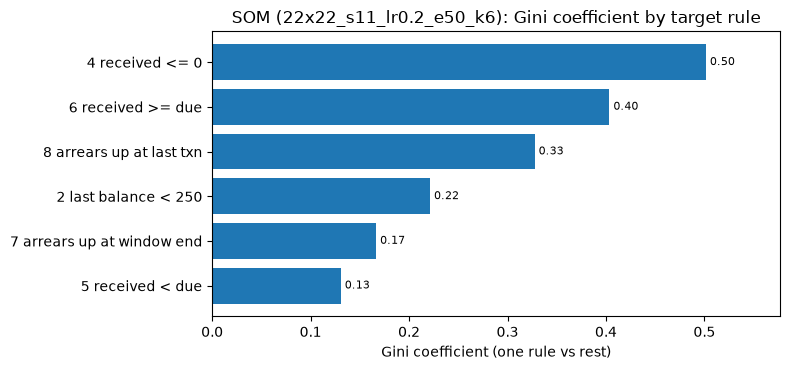

In [10]:
tbl = best_tbl.dropna(subset=["gini"]).sort_values("gini")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(tbl["rule_name"], tbl["gini"])
for i, v in enumerate(tbl["gini"]):
    ax.text(v, i, f" {v:.2f}", va="center", fontsize=8)
ax.set_xlabel("Gini coefficient (one rule vs rest)")
ax.set_title(f"{METHOD.upper()} ({best_id}): Gini coefficient by target rule")
ax.set_xlim(0, max(0.1, tbl["gini"].max() * 1.15))
plt.tight_layout(); plt.show()

In [11]:
pd.DataFrame({OBS_ID: obs_ids.to_numpy(), "cluster": best_labels,
              "target_rule": rule_arr}).to_csv(OUT_DIR / f"{METHOD}_best_assignments.csv", index=False)
print("Saved outputs to:", OUT_DIR.resolve())

Saved outputs to: /Users/emmadevilliers/Documents/GitHub/MOR-assignment3/som_gini_output
